In [319]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay


Load the dataset

In [320]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Training Dataset:")
print(train.head())

print("\nTesting Dataset:")
print(test.head())

Training Dataset:
         id sexo  longitudCraneo  longitudPico  longitudNarina  anchoCraneo  \
0  0J4_2016    H          174.18        106.85           80.19        52.43   
1  A68_2016    H          171.12        104.59           79.45        51.14   
2  E55_2015    H          174.69        106.83           82.14        49.09   
3  7C7_2016    M          182.25        113.17           84.13        52.26   
4  2C0_2018    H          173.70        105.19           80.37        49.20   

   altoPico  anchoPico  tarso  longAlaCerrada  longAlaAbierta  \
0     30.20      23.26  88.74            51.0            95.7   
1     30.61      24.04  90.22            50.5            94.4   
2     30.60      26.47  91.42            52.7            96.6   
3     32.08      26.07  91.74            52.6            98.9   
4     34.00      27.12  87.77            50.8            94.5   

   mediaEnvergadura  envergadura  peso  
0             104.2        208.4  2.38  
1             102.2        204.4  

In [321]:
print("Training Shape:", train.shape)

print("Testing Shape:", test.shape)

print("\nDataset Information:")
train.info()

print("\nColumn Names:")
print(train.columns)

print("\nStatistical Description:")
print(train.describe())

Training Shape: (94, 14)
Testing Shape: (41, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB

Column Names:
Index

Check missing values

In [322]:
train.isnull().sum()

,0
id,0
sexo,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0


In [323]:
test.isnull().sum()

,0
id,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0
longAlaAbierta,0


Check duplicate values

In [324]:
print("duplicate train",train.duplicated().sum())
print("duplicate test",test.duplicated().sum())

duplicate train 0
duplicate test 0


Identify numerical and categorical columns

In [325]:
cat_col=train.select_dtypes(include='object').columns
cat_col

Index(['id', 'sexo'], dtype='object')

In [326]:
cat_col=test.select_dtypes(include='object').columns
cat_col

Index(['id'], dtype='object')

In [327]:
num_col=train.select_dtypes(exclude='object').columns
num_col

Index(['longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo',
       'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta',
       'mediaEnvergadura', 'envergadura', 'peso'],
      dtype='object')

In [328]:
num_col=test.select_dtypes(exclude='object').columns
num_col

Index(['longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo',
       'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta',
       'mediaEnvergadura', 'envergadura', 'peso'],
      dtype='object')

Analyze target variable

In [329]:
train["sexo"].value_counts()

,count
sexo,
H,57
M,37


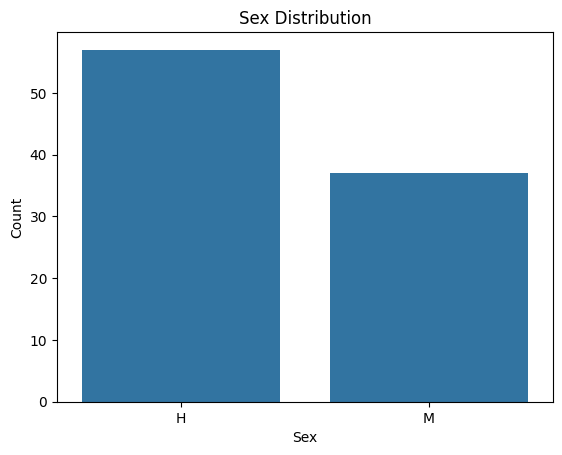

In [330]:
sns.countplot(data=train, x='sexo')

plt.title("Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Count")

plt.show()

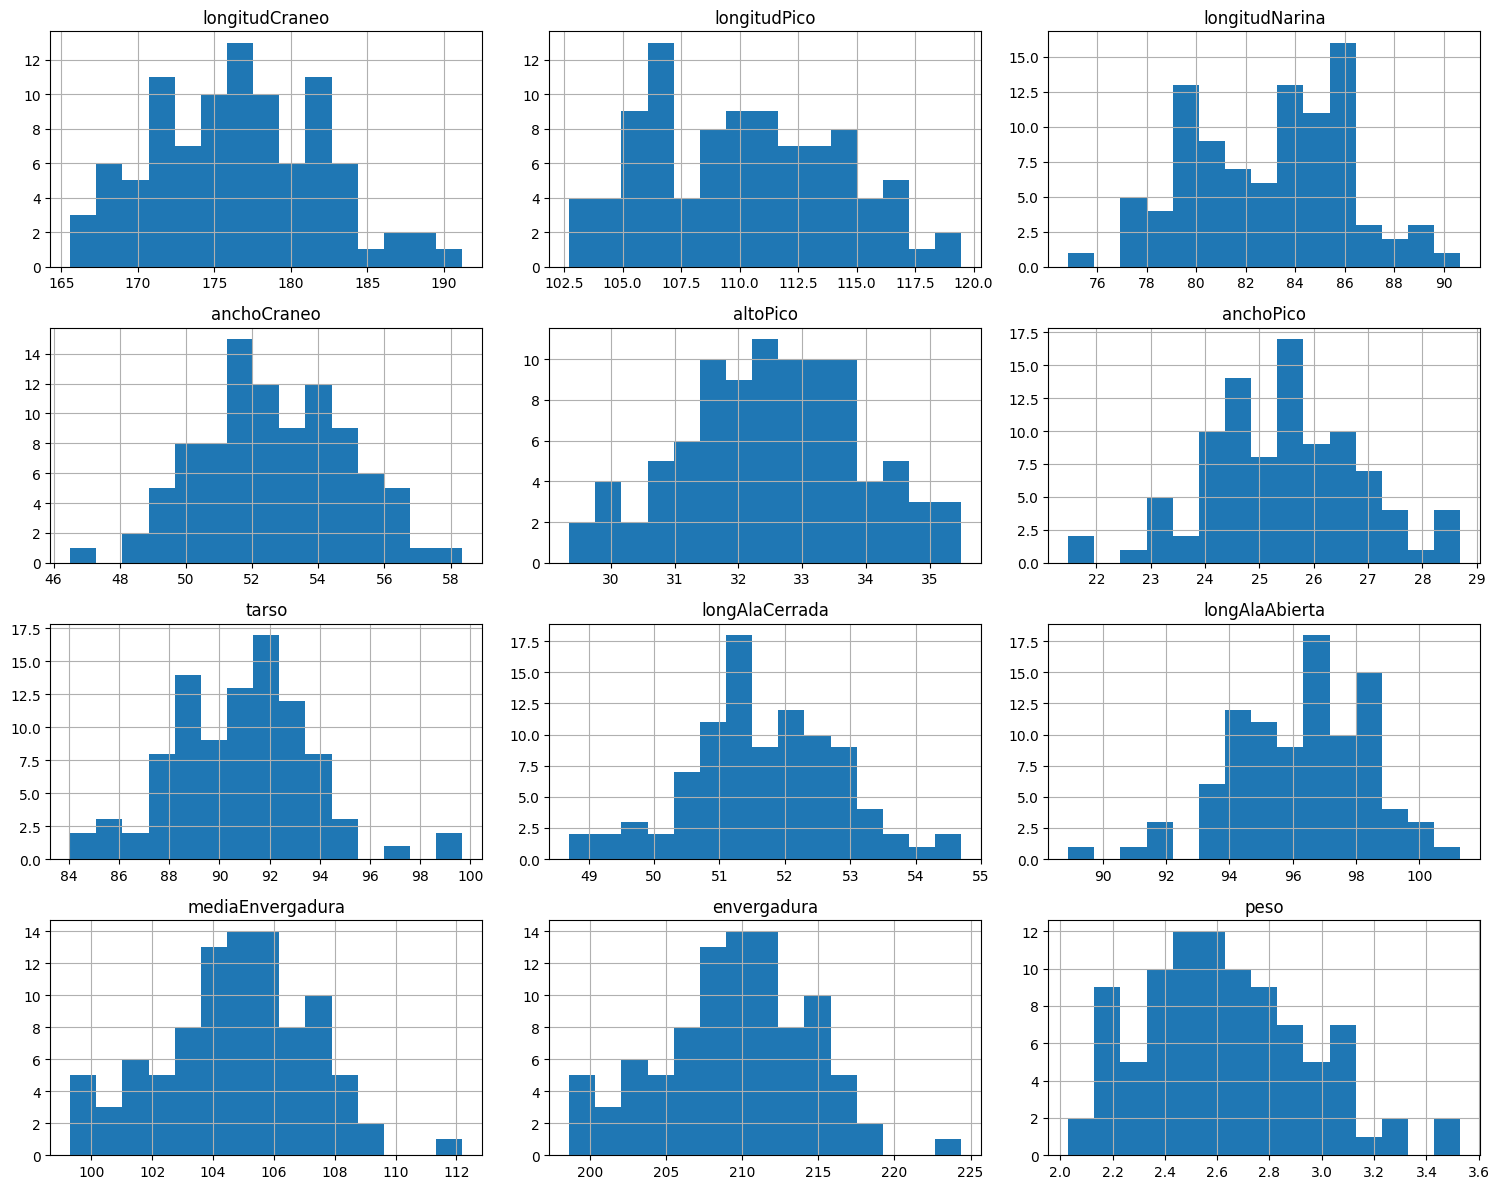

In [331]:
train.hist(figsize=(15, 12), bins=15)

plt.tight_layout()
plt.show()

Analyze target variable

In [332]:
X = train.drop(['id', 'sexo'], axis=1)

y = train['sexo']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   longitudCraneo  longitudPico  longitudNarina  anchoCraneo  altoPico  \
0          174.18        106.85           80.19        52.43     30.20   
1          171.12        104.59           79.45        51.14     30.61   
2          174.69        106.83           82.14        49.09     30.60   
3          182.25        113.17           84.13        52.26     32.08   
4          173.70        105.19           80.37        49.20     34.00   

   anchoPico  tarso  longAlaCerrada  longAlaAbierta  mediaEnvergadura  \
0      23.26  88.74            51.0            95.7             104.2   
1      24.04  90.22            50.5            94.4             102.2   
2      26.47  91.42            52.7            96.6             105.2   
3      26.07  91.74            52.6            98.9             107.6   
4      27.12  87.77            50.8            94.5             103.7   

   envergadura  peso  
0        208.4  2.38  
1        204.4  2.14  
2        210.4  2.50  
3       

Handle unknown and missing values

In [333]:
X = X.replace(['unknown', 'Unknown', '?', ''], np.nan)

test_features = test.drop(['id'], axis=1)

test_features = test_features.replace(
    ['unknown', 'Unknown', '?', ''], np.nan
)

X = X.apply(pd.to_numeric, errors='coerce')

test_features = test_features.apply(
    pd.to_numeric, errors='coerce'
)

In [334]:
imputer = SimpleImputer(strategy='median')

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

test_features = pd.DataFrame(
    imputer.transform(test_features),
    columns=X.columns
)

print("Missing Values After Imputation:")
print(X.isnull().sum())

Missing Values After Imputation:
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                0
dtype: int64


In [335]:
# Combine features and target

datdata = train.drop(columns=['id'])

data = datdata.dropna()

print("Missing Values:")
print(data.isnull().sum())

print("Cleaned Dataset Shape:", data.shape)

Missing Values:
sexo                0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                0
dtype: int64
Cleaned Dataset Shape: (93, 13)


In [336]:
X = data.drop(columns=['sexo'])

y = data['sexo']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   longitudCraneo  longitudPico  longitudNarina  anchoCraneo  altoPico  \
0          174.18        106.85           80.19        52.43     30.20   
1          171.12        104.59           79.45        51.14     30.61   
2          174.69        106.83           82.14        49.09     30.60   
3          182.25        113.17           84.13        52.26     32.08   
4          173.70        105.19           80.37        49.20     34.00   

   anchoPico  tarso  longAlaCerrada  longAlaAbierta  mediaEnvergadura  \
0      23.26  88.74            51.0            95.7             104.2   
1      24.04  90.22            50.5            94.4             102.2   
2      26.47  91.42            52.7            96.6             105.2   
3      26.07  91.74            52.6            98.9             107.6   
4      27.12  87.77            50.8            94.5             103.7   

   envergadura  peso  
0        208.4  2.38  
1        204.4  2.14  
2        210.4  2.50  
3       

Split training and testing data

- 80% training data.
- 20% validation data.

In [337]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)



X_train: (74, 12)
X_test: (19, 12)
y_train: (74,)
y_test: (19,)


Feature scaling
StandardScaler converts numerical values into a common scale.

In [338]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

Scaled Training Data:
[[ 0.34761951  1.13296534  0.77653155 -0.01108903  1.49765091 -1.54036369
   1.31119086  0.59558648  0.07832555 -0.34058273 -0.34058273 -0.29994306]
 [ 0.25115269  0.09915274 -0.0873598   0.42529297  2.05484987  0.6965988
  -0.66852849 -1.15146719 -0.6744135  -0.55924595 -0.55924595 -0.42376892]
 [-0.07490519  0.05136091  0.27825714  0.67194367 -0.27974323  0.58440005
   1.1580634   0.19852883  0.8310646   0.92766391  0.92766391  1.06214146]
 [ 1.42997731  0.47142589  0.75064717  1.42138232  1.27900322  0.67556154
   0.81170366 -0.67499801  0.02814295  1.19005977  1.19005977  0.3810992 ]
 [-0.26976818 -0.58502495 -0.69564285 -0.86962318 -0.27269008  0.21975413
   0.38878019 -0.03970577  0.32923857  0.53407013  0.53407013 -1.35246291]]


In [339]:

# Feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training Shape:", X_train_scaled.shape)
print("Validation Shape:", X_test_scaled.shape)

Training Shape: (74, 12)
Validation Shape: (19, 12)


Model building and training




Logistic Regression


In [340]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))

Logistic Regression Accuracy: 0.8421052631578947


RANDOM FOREST

In [341]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.8421052631578947


Support Vector Machine (SVM)

In [342]:
svm = SVC()

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.7368421052631579


Gradient Boosting Classifier

In [343]:
gb = GradientBoostingClassifier(
    random_state=42
)

gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)

print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, gb_pred))

Gradient Boosting Accuracy: 0.8421052631578947


Compare all models

In [344]:
models = {
    'Logistic Regression': lr_pred,
    'Random Forest': rf_pred,
    'SVM': svm_pred,
    'Gradient Boosting': gb_pred
}

for name, predictions in models.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    print(name, ":", accuracy * 100, "%")

Logistic Regression : 84.21052631578947 %
Random Forest : 84.21052631578947 %
SVM : 73.68421052631578 %
Gradient Boosting : 84.21052631578947 %


The classification report provides:
- Precision
- Recall
- F1-score
- Support

In [345]:
print(classification_report(
    y_test,
    lr_pred
))

              precision    recall  f1-score   support

           H       0.85      0.92      0.88        12
           M       0.83      0.71      0.77         7

    accuracy                           0.84        19
   macro avg       0.84      0.82      0.82        19
weighted avg       0.84      0.84      0.84        19



[[11  1]
 [ 2  5]]


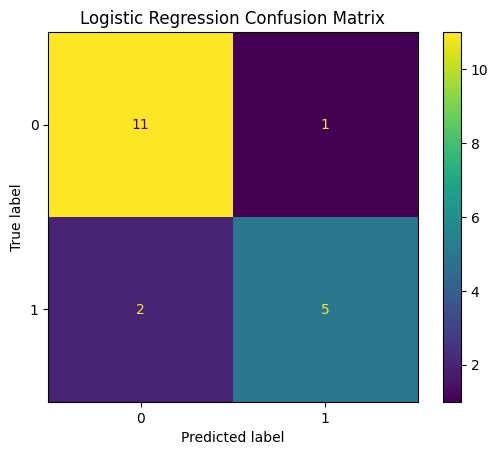

In [346]:
cm = confusion_matrix(
    y_test,
    lr_pred
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

plt.title("Logistic Regression Confusion Matrix")

plt.show()

Hyperparameter tuning

In [347]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'],
    'max_iter': [1000, 2000]
}

grid_search = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(
    X_train_scaled,
    y_train
)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Score:")
print(grid_search.best_score_)

Best Parameters:
{'C': 0.1, 'max_iter': 1000, 'solver': 'lbfgs'}

Best Cross Validation Score:
0.9333333333333333


In [348]:
best_model = grid_search.best_estimator_

tuned_pred = best_model.predict(
    X_test_scaled
)

print("Tuned Model Accuracy:",
      accuracy_score(y_test, tuned_pred))

print("\nClassification Report:")

print(classification_report(
    y_test,
    tuned_pred
))

Tuned Model Accuracy: 0.8421052631578947

Classification Report:
              precision    recall  f1-score   support

           H       0.85      0.92      0.88        12
           M       0.83      0.71      0.77         7

    accuracy                           0.84        19
   macro avg       0.84      0.82      0.82        19
weighted avg       0.84      0.84      0.84        19



Final prediction using test.csv

In [349]:
# Keep test IDs separately

test_ids = test['id']

# Remove ID column

X_test = test.drop(['id'], axis=1)

# Handle unknown values

X_test = X_test.replace(
    ['unknown', 'Unknown', '?', ''], np.nan
)

X_test = X_test.apply(
    pd.to_numeric, errors='coerce'
)

# Fill missing values using training imputer

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

# Apply the same scaler

X_test_scaled = scaler.transform(X_test)

print("Test Data Shape:", X_test_scaled.shape)

Test Data Shape: (41, 12)


In [350]:
from sklearn.base import clone

# Prepare complete training data

X_full = train.drop(['id', 'sexo'], axis=1)

y_full = train['sexo']

X_full = X_full.replace(
    ['unknown', 'Unknown', '?', ''], np.nan
)

X_full = X_full.apply(
    pd.to_numeric, errors='coerce'
)

# Fit imputer on all training data

final_imputer = SimpleImputer(strategy='median')

X_full_imputed = final_imputer.fit_transform(X_full)

# Fit scaler on all training data

final_scaler = StandardScaler()

X_full_scaled = final_scaler.fit_transform(
    X_full_imputed
)

# Create final tuned model

final_model = clone(best_model)

# Train final model

final_model.fit(X_full_scaled, y_full)

print("Final Model Training Completed")

Final Model Training Completed


Predict test data

In [351]:
# Prepare test features

X_test = test.drop(['id'], axis=1)

X_test = X_test.replace(
    ['unknown', 'Unknown', '?', ''], np.nan
)

X_test = X_test.apply(
    pd.to_numeric, errors='coerce'
)

# Apply training imputer

X_test_imputed = final_imputer.transform(X_test)

# Apply training scaler

X_test_scaled = final_scaler.transform(
    X_test_imputed
)

# Generate predictions

predictions = final_model.predict(
    X_test_scaled
)

print("Predictions:")
print(predictions)

print("Total Predictions:", len(predictions))

Predictions:
['M' 'H' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'H' 'H' 'H' 'M' 'H' 'H' 'H' 'H'
 'H' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'M' 'M' 'M' 'M' 'M' 'H' 'M' 'H' 'H'
 'H' 'H' 'M' 'M' 'M']
Total Predictions: 41


Create submission.csv

In [352]:
submission = pd.DataFrame({
    'id': test['id'],
    'sexo': predictions
})

print(submission.head())

print("Submission Shape:", submission.shape)

# Check missing values

print(submission.isnull().sum())

# Save CSV file

submission.to_csv(
    'submission.csv',
    index=False
)

print("Submission File Created Successfully!")

         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M
Submission Shape: (41, 2)
id      0
sexo    0
dtype: int64
Submission File Created Successfully!


In [353]:
check = pd.read_csv('submission.csv')

print(check.head())

print("\nTotal Rows:", len(check))

print("\nColumn Names:")
print(check.columns.tolist())

print("\nMissing Values:")
print(check.isnull().sum())

print("\nPredicted Classes:")
print(check['sexo'].value_counts())

assert len(check) == len(test)
assert check.columns.tolist() == ['id', 'sexo']
assert check.isnull().sum().sum() == 0

print("\nSubmission File is Ready!")

         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M

Total Rows: 41

Column Names:
['id', 'sexo']

Missing Values:
id      0
sexo    0
dtype: int64

Predicted Classes:
sexo
M    21
H    20
Name: count, dtype: int64

Submission File is Ready!
